<a href="https://colab.research.google.com/github/Juniormaina/Junior-Antony-Maina-Builder-Software-Developer/blob/main/Copy_of_Qiskit101_HandsOn_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Qiskit 101: Hands-on with the Qiskit SDK

**Qiskit Fall Fest 2026 · AstraCode Community** · Instructor: Dr. Muhammad Faryad (LUMS)

You already know what a qubit is. Today is about **Qiskit**, the open-source SDK we use to write, simulate and run quantum programs.

| Part | What you will do | Time |
|---|---|---|
| 0 | Set up Qiskit in Colab | 3 min |
| 1 | Build and inspect circuits with `QuantumCircuit` | 8 min |
| 2 | Quiz: Bell states, SWAP and GHZ | 12 min |
| 3 | Get measurement counts with the **Sampler** | 10 min |
| 4 | Get expectation values with the **Estimator** and `SparsePauliOp` | 15 min |
| 5 | *Bonus (take-home):* simulate a noisy IBM device | — |

Everything runs on simulators. You do **not** need an IBM account today.

**How the exercises work:** look for `# YOUR CODE HERE`. Most exercises end with a `check(...)` call that prints ✅ or ❌.

## Part 0 · Setup

Run the next cell once. It installs Qiskit in Colab. It takes about a minute.

In [1]:
%pip install -q "qiskit[visualization]"

In [2]:
import qiskit
print("Qiskit version:", qiskit.__version__)   # this notebook was tested with Qiskit 2.6

Qiskit version: 2.6.1


Now the imports for the whole notebook, plus a small `check` helper for the exercises.

In [3]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.visualization import plot_histogram, plot_distribution, plot_state_qsphere
from IPython.display import display


def check(qc, target):
    # Compare the state made by `qc` with `target` (ignoring a global phase).
    target = target if isinstance(target, Statevector) else Statevector(target)
    state = Statevector(qc)
    if state.equiv(target):
        print("✅ Correct!")
    else:
        print("❌ Not yet. Your circuit makes this state:")
        display(state.draw("latex"))

## Part 1 · The `QuantumCircuit` object

A Qiskit program starts with a `QuantumCircuit`. You add gates by calling methods on it. Each method takes the qubit index (or indices) it acts on.

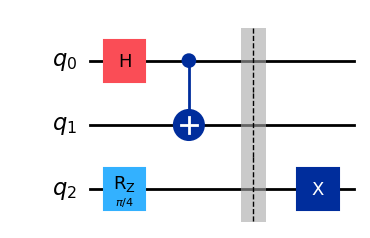

In [4]:
qc = QuantumCircuit(3)       # 3 qubits, all start in |0>
qc.h(0)                      # Hadamard on qubit 0
qc.cx(0, 1)                  # CNOT: control 0, target 1
qc.rz(np.pi / 4, 2)          # Z-rotation by pi/4 on qubit 2
qc.barrier()                 # a visual separator (and a hint to the compiler)
qc.x(2)

qc.draw("mpl")

A circuit is also a data structure you can inspect. This becomes important once circuits get large.

In [5]:
print("qubits:", qc.num_qubits)
print("depth: ", qc.depth())        # longest path through the circuit
print("size:  ", qc.size())         # total number of operations
print("gates: ", dict(qc.count_ops()))

for instruction in qc.data:         # every operation, in order
    name = instruction.operation.name
    qubits = [qc.find_bit(q).index for q in instruction.qubits]
    print(f"  {name:8s} on qubits {qubits}")

qubits: 3
depth:  3
size:   4
gates:  {'h': 1, 'cx': 1, 'rz': 1, 'barrier': 1, 'x': 1}
  h        on qubits [0]
  cx       on qubits [0, 1]
  rz       on qubits [2]
  barrier  on qubits [0, 1, 2]
  x        on qubits [2]


### Getting the state: `Statevector`

`Statevector(qc)` simulates the circuit exactly and returns its state. Use it to debug small circuits (it does not scale past ~30 qubits).

<IPython.core.display.Latex object>

{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


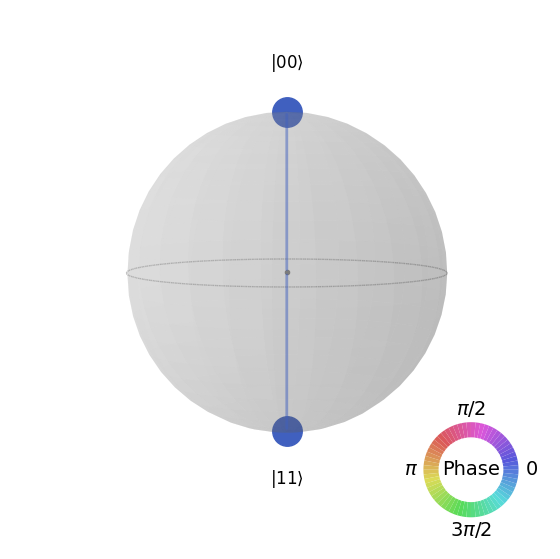

In [6]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

psi = Statevector(bell)
display(psi.draw("latex"))
print(psi.probabilities_dict())
plot_state_qsphere(psi)

### ⚠️ The #1 Qiskit gotcha: qubit ordering

Qiskit is **little-endian**. Qubit 0 is the **rightmost** bit in a label. So `|001⟩` means qubit 0 is 1.

In [ ]:
qc = QuantumCircuit(3)
qc.x(0)                                  # flip qubit 0 only
print(Statevector(qc).probabilities_dict())   # -> {'001': 1.0}

{np.str_('001'): np.float64(1.0)}


### Exercise 1 · Warm-up

Build a one-qubit circuit that makes $\;|{-i}\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle - i|1\rangle\right)$.

*Hint:* start with `h`, then add a phase with `s` or `sdg`.

In [ ]:
ex1 = QuantumCircuit(1)
# YOUR CODE HERE


check(ex1, [1/np.sqrt(2), -1j/np.sqrt(2)])

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

## Part 2 · Quiz: multi-qubit circuits

Two-qubit gates you will need:

```python
qc.cx(c, t)     # CNOT, control c, target t
qc.cz(c, t)     # controlled-Z
qc.swap(a, b)   # swap qubits a and b
```

Remember the ordering rule: in $|01\rangle$, qubit **1** is 0 and qubit **0** is 1.

### Exercise 2a · Bell state $|\Phi^+\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle + |11\rangle\right)$

Write it as a function. We will reuse these functions later.

In [ ]:
def phi_plus():
    qc = QuantumCircuit(2)
    # YOUR CODE HERE

    return qc


check(phi_plus(), [1/np.sqrt(2), 0, 0, 1/np.sqrt(2)])

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

### Exercise 2b · Bell state $|\Psi^-\rangle = \frac{1}{\sqrt{2}}\left(|01\rangle - |10\rangle\right)$

Perfectly anti-correlated, with a minus sign.

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

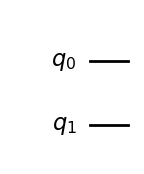

In [ ]:
def psi_minus():
    qc = QuantumCircuit(2)
    # YOUR CODE HERE

    return qc


check(psi_minus(), [0, 1/np.sqrt(2), -1/np.sqrt(2), 0])
psi_minus().draw("mpl")

### Exercise 2c · Swap the qubits

`given()` prepares some state. Add **one** gate so that qubit 0 and qubit 1 trade states.

In [ ]:
def given():
    qc = QuantumCircuit(2)
    qc.rx(np.pi / 3, 0)
    qc.x(1)
    return qc


def swapped():
    qc = given()
    # YOUR CODE HERE (one line)

    return qc


# target: the same gates, applied to the other qubits
target = QuantumCircuit(2)
target.rx(np.pi / 3, 1)
target.x(0)
check(swapped(), Statevector(target))

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

### Exercise 2d · GHZ state on *n* qubits

$|\mathrm{GHZ}_n\rangle = \frac{1}{\sqrt{2}}\left(|0\cdots0\rangle + |1\cdots1\rangle\right)$

This is where code beats drag-and-drop: write **one** function that works for any `n`. Use a `for` loop.

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

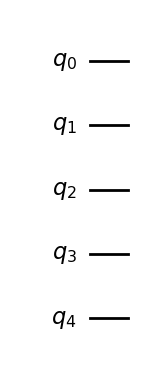

In [ ]:
def ghz(n):
    qc = QuantumCircuit(n)
    # YOUR CODE HERE

    return qc


target = np.zeros(2**3)
target[0] = target[-1] = 1/np.sqrt(2)
check(ghz(3), target)
ghz(5).draw("mpl")

## Part 3 · The Sampler: from circuits to counts

`Statevector` is a debugging tool. A real quantum computer never hands you the state. It gives you **measurement outcomes**.

Qiskit talks to any quantum computer, real or simulated, through two **primitives**:

| Primitive | You give it | You get back |
|---|---|---|
| **Sampler** | circuits *with* measurements | bitstrings / counts |
| **Estimator** | circuits *without* measurements + observables | expectation values ⟨O⟩ |

Today we use the reference simulators `StatevectorSampler` and `StatevectorEstimator`. On real hardware the code looks the same. Only the primitive object changes.

The input to a primitive is a **PUB** (primitive unified bloc). For the Sampler, a PUB is a circuit, optionally with parameter values and a shot count.

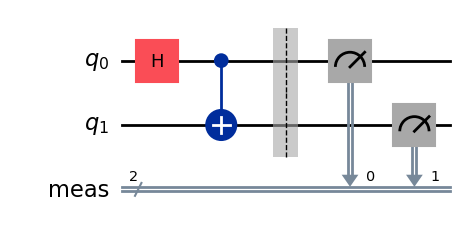

{'11': 497, '00': 503}


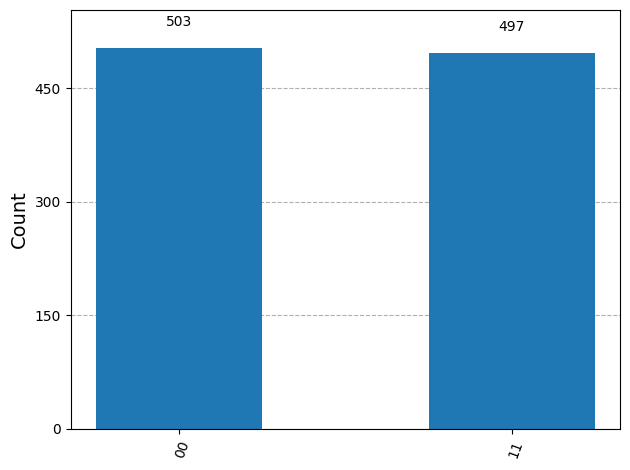

In [ ]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.measure_all()          # adds measurements into a register named "meas"
display(bell.draw("mpl"))

sampler = StatevectorSampler(seed=42)
job = sampler.run([bell], shots=1000)   # a list of PUBs
result = job.result()

pub_result = result[0]                  # one result per PUB
counts = pub_result.data.meas.get_counts()
print(counts)
plot_histogram(counts)

The register name matters: `measure_all()` names it `meas`, so the data lives in `.data.meas`. You can also see every shot in order:

In [ ]:
print(pub_result.data.meas.get_bitstrings()[:10])
print("shots:", pub_result.data.meas.num_shots)

['11', '00', '11', '11', '00', '11', '11', '11', '00', '00']
shots: 1000


### Exercise 3a · Many circuits, one job

Run all four circuits from Part 2 in **one** `sampler.run` call with 2000 shots. Then plot them together.

*Hint:* `circuit.measure_all(inplace=False)` returns a measured copy and leaves the original alone.

In [ ]:
circuits = [phi_plus(), psi_minus(), swapped(), ghz(3)]
labels = ["Φ+", "Ψ−", "swapped", "GHZ-3"]
measured = [c.measure_all(inplace=False) for c in circuits]

# YOUR CODE HERE: run `measured` with the sampler, 2000 shots,
# and build a list `counts_list` with one counts dict per circuit.
counts_list = []


if counts_list:
    display(plot_distribution(counts_list, legend=labels, figsize=(10, 4)))

### Exercise 3b · Where the Sampler runs out

Build $|\Phi^-\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle - |11\rangle\right)$ and sample it next to $|\Phi^+\rangle$.

Can you tell them apart from the counts?

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

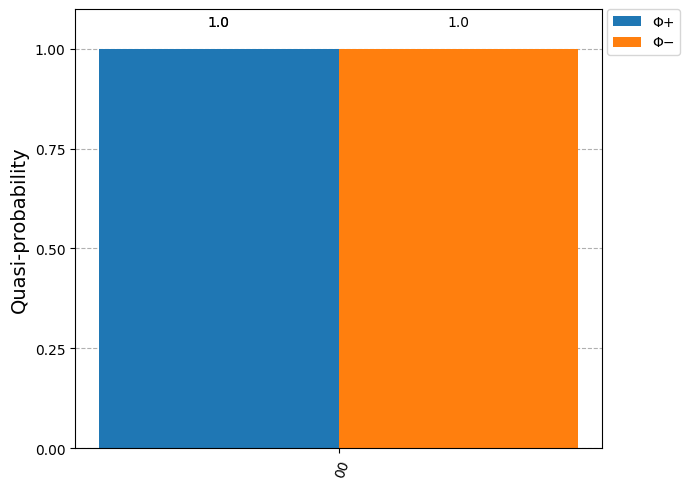

In [ ]:
def phi_minus():
    qc = QuantumCircuit(2)
    # YOUR CODE HERE

    return qc


check(phi_minus(), [1/np.sqrt(2), 0, 0, -1/np.sqrt(2)])

res = sampler.run([phi_plus().measure_all(inplace=False),
                   phi_minus().measure_all(inplace=False)], shots=2000).result()
plot_distribution([r.data.meas.get_counts() for r in res], legend=["Φ+", "Φ−"])

Same histogram. The minus sign is a **relative phase**, and measuring in the Z basis cannot see it.

To see it, we measure other quantities, such as ⟨XX⟩. That is the Estimator's job.

## Part 4 · The Estimator and observables

### Observables with `SparsePauliOp`

An observable is a weighted sum of Pauli strings. The same ordering rule applies: the **rightmost** character acts on qubit 0.

In [ ]:
ZZ = SparsePauliOp("ZZ")
ZI = SparsePauliOp("ZI")        # Z on qubit 1, identity on qubit 0
H = SparsePauliOp.from_list([("ZZ", 1.0), ("XX", 0.5), ("IZ", -0.2)])

print(H)
print("num_qubits:", H.num_qubits)

# They behave like operators: add, scale, multiply, tensor
print((ZZ + 2 * ZI).simplify())
print(SparsePauliOp("X").tensor(SparsePauliOp("Z")))   # X ⊗ Z  ->  "XZ"

SparsePauliOp(['ZZ', 'XX', 'IZ'],
              coeffs=[ 1. +0.j,  0.5+0.j, -0.2+0.j])
num_qubits: 2
SparsePauliOp(['ZZ', 'ZI'],
              coeffs=[1.+0.j, 2.+0.j])
SparsePauliOp(['XZ'],
              coeffs=[1.+0.j])


### Running the Estimator

Two rules:
- the circuit has **no measurements**;
- a PUB is `(circuit, observables)`. You can pass a whole list of observables in one PUB.

In [ ]:
estimator = StatevectorEstimator()

bell = QuantumCircuit(2)     # |Φ+>, no measurements
bell.h(0)
bell.cx(0, 1)

names = ["ZZ", "XX", "YY", "ZI", "IZ"]
observables = [SparsePauliOp(p) for p in names]

job = estimator.run([(bell, observables)])
evs = job.result()[0].data.evs

for name, value in zip(names, evs):
    print(f"<{name}> = {value:+.3f}")

<ZZ> = +1.000
<XX> = +1.000
<YY> = -1.000
<ZI> = +0.000
<IZ> = +0.000


Read this like a physicist:
- ⟨ZZ⟩ = +1: the two qubits always agree in the Z basis.
- ⟨ZI⟩ = ⟨IZ⟩ = 0: each qubit on its own looks completely random.

Perfect joint correlation with random parts is the signature of entanglement.

The reference estimator is exact. To mimic finite shots, ask for a target `precision`:

In [ ]:
noisy = StatevectorEstimator(seed=7).run([(bell, observables)], precision=0.05).result()[0]
print("exact:          ", np.round(evs, 3))
print("precision=0.05: ", np.round(noisy.data.evs, 3))

exact:           [ 1.  1. -1.  0.  0.]
precision=0.05:  [ 1.     1.015 -1.014 -0.045 -0.023]


### Exercise 4a · A fingerprint for each Bell state

Complete `psi_plus()` for $|\Psi^+\rangle = \frac{1}{\sqrt{2}}\left(|01\rangle + |10\rangle\right)$.

Then compute ⟨ZZ⟩, ⟨XX⟩, ⟨YY⟩ for all four Bell states in **one** `estimator.run` call (four PUBs).

In [ ]:
def psi_plus():
    qc = QuantumCircuit(2)
    # YOUR CODE HERE

    return qc


check(psi_plus(), [0, 1/np.sqrt(2), 1/np.sqrt(2), 0])

bell_states = {"Φ+": phi_plus(), "Φ−": phi_minus(), "Ψ+": psi_plus(), "Ψ−": psi_minus()}
fingerprint_obs = [SparsePauliOp(p) for p in ["ZZ", "XX", "YY"]]

# YOUR CODE HERE: build one PUB per Bell state and run them together.
pubs = []
results = []


for name, r in zip(bell_states, results):
    zz, xx, yy = r.data.evs
    print(f"{name}:  <ZZ>={zz:+.0f}  <XX>={xx:+.0f}  <YY>={yy:+.0f}")

❌ Not yet. Your circuit makes this state:


<IPython.core.display.Latex object>

Every Bell state has a different sign pattern. ⟨XX⟩ is what separates Φ+ from Φ−, which the Sampler could not do.

### Exercise 4b · Identify the mystery state

`mystery()` makes one of the four Bell states, but it is disguised. Use **only the Estimator** to find out which one.

In [ ]:
def mystery():
    qc = QuantumCircuit(2)
    qc.ry(np.pi / 2, 1)
    qc.cx(1, 0)
    qc.s(0)
    qc.s(1)
    return qc


# YOUR CODE HERE: estimate <ZZ>, <XX>, <YY> for mystery() and compare with your table.

### Exercise 4c · Challenge: violate a Bell inequality (CHSH)

Alice holds qubit 0 and Bob holds qubit 1. They measure:

- Alice: $A_0 = Z$, $A_1 = X$
- Bob: $B_0 = \frac{Z + X}{\sqrt{2}}$, $B_1 = \frac{Z - X}{\sqrt{2}}$

Any local classical theory obeys

$$S = \langle A_0B_0\rangle + \langle A_0B_1\rangle + \langle A_1B_0\rangle - \langle A_1B_1\rangle \;\le\; 2 .$$

Compute $S$ for $|\Phi^+\rangle$ (the `bell` circuit above) with one Estimator PUB. Quantum mechanics allows up to $2\sqrt{2} \approx 2.83$.

*Hint:* `B.tensor(A)` builds $B \otimes A$, with $A$ on qubit 0.

In [ ]:
Z, X = SparsePauliOp("Z"), SparsePauliOp("X")
A0, A1 = Z, X
B0 = (Z + X) / np.sqrt(2)
B1 = (Z - X) / np.sqrt(2)

# YOUR CODE HERE: build the four correlators, run one PUB, and compute S.
S = None


print("S =", S)

S = None


## Part 5 · Bonus (take-home): a noisy IBM device on your laptop

Real hardware adds two things we skipped today:

1. **Transpilation.** The device has a fixed set of native gates and limited connectivity. The transpiler rewrites your circuit into an *ISA circuit* the device can run.
2. **Noise.** Gates and readout are imperfect.

The `fake_provider` in `qiskit-ibm-runtime` contains snapshots of real IBM devices, including their noise. You can run them locally, still with no account.

In [ ]:
%pip install -q qiskit-ibm-runtime qiskit-aer

before: {'measure': 4, 'cx': 3, 'h': 1, 'barrier': 1} depth 5
after:  {'rz': 14, 'sx': 7, 'measure': 4, 'cz': 3, 'barrier': 1} depth 16


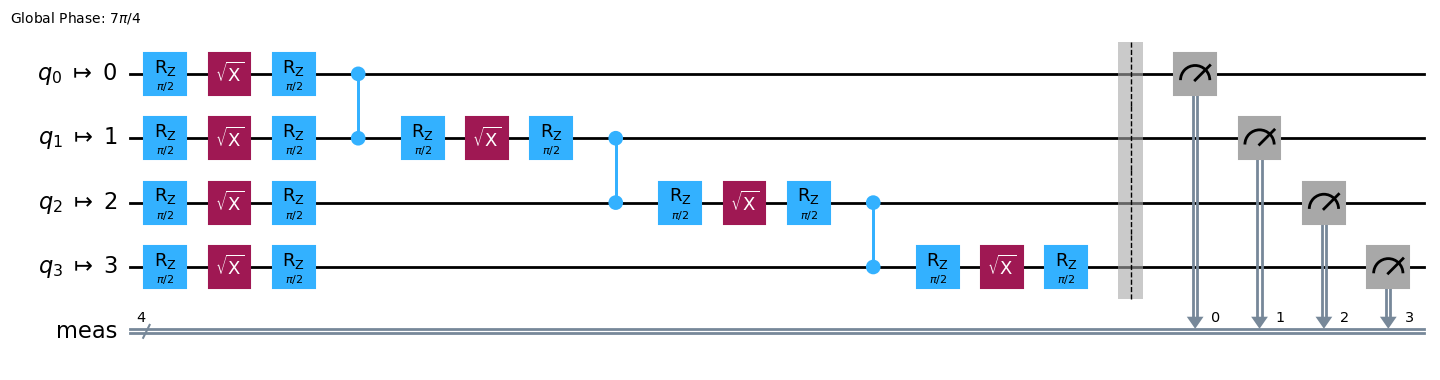

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeFez      # 156-qubit IBM Heron snapshot
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.primitives import BackendSamplerV2

backend = FakeFez()
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

circuit = QuantumCircuit(4)        # 4-qubit GHZ
circuit.h(0)
for i in range(3):
    circuit.cx(i, i + 1)
circuit.measure_all()
isa_circuit = pm.run(circuit)

print("before:", dict(circuit.count_ops()), "depth", circuit.depth())
print("after: ", dict(isa_circuit.count_ops()), "depth", isa_circuit.depth())
isa_circuit.draw("mpl", idle_wires=False, fold=-1)

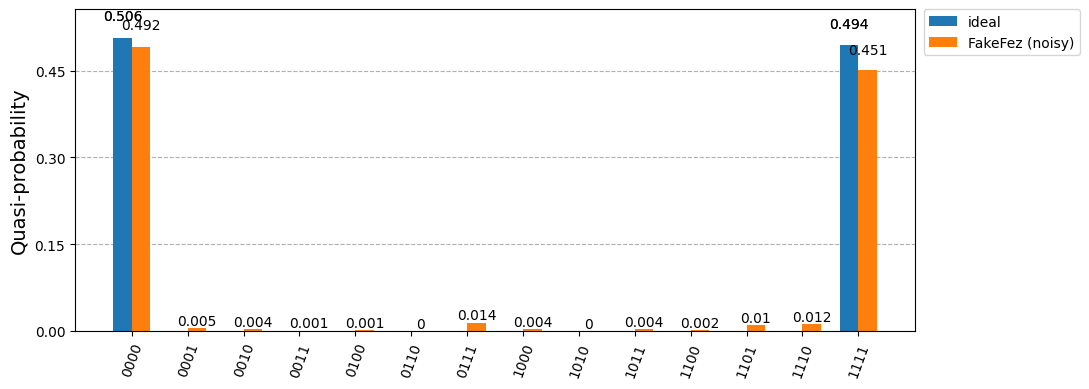

In [ ]:
noisy_counts = BackendSamplerV2(backend=backend).run([isa_circuit], shots=4000).result()[0].data.meas.get_counts()
ideal_counts = sampler.run([circuit], shots=4000).result()[0].data.meas.get_counts()

plot_distribution([ideal_counts, noisy_counts], legend=["ideal", "FakeFez (noisy)"], figsize=(11, 4))

The noisy run shows bitstrings that should never appear. Reducing that error is a big part of current research. The Qiskit docs cover error suppression and mitigation in detail.

**Ready for a real QPU?** Create a free account on the [IBM Quantum Platform](https://quantum.cloud.ibm.com/). The Open plan includes 10 minutes of QPU time per month. Then follow the current [Qiskit Runtime guide](https://quantum.cloud.ibm.com/docs/en/guides/get-started-with-primitives). The Runtime primitive classes are being reworked as of `qiskit-ibm-runtime` 0.50, so use the docs rather than older code samples.

## What you learned today

- `QuantumCircuit`: build, draw and inspect circuits; qubit 0 is the rightmost bit.
- `Statevector`: exact states for debugging small circuits.
- **Sampler**: circuits with measurements → counts. Many PUBs, one job.
- **Estimator** + `SparsePauliOp`: circuits without measurements → expectation values. It sees phases that counts miss.

### Keep going
- [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning): free courses, from *Basics of Quantum Information* to *Variational Algorithm Design*.
- [Qiskit documentation](https://quantum.cloud.ibm.com/docs/en/guides)
- **IBM Certified Quantum Computation using Qiskit v2.X Developer.** Today's topics (circuits, primitives, observables) are core exam material.

In [ ]:
import qiskit, sys
print("Python:", sys.version.split()[0])
print("Qiskit:", qiskit.__version__)

Python: 3.13.16
Qiskit: 2.6.1


---
Adapted by Muhammad Faryad (October 2026) from the IBM notebook *First Step into Quantum Computing* (created by Sophy Shin, reviewed by Nate Earnest-Noble). Changes: refocused on the Qiskit SDK, simulator-only, Colab-ready, new Sampler and Estimator sections.

<div class="alert alert-info">

© IBM Corp., 2025. This is licensed under the Apache License, Version 2.0. You may obtain a copy of this license at http://www.apache.org/licenses/LICENSE-2.0. Any modifications or derivative works of this must retain this copyright notice, and modified files need to carry a notice indicating that they have been altered from the originals.
</div>